# Sentiment analysis on SST-2 and IMDB — TF-IDF + classic ML, with hyperparameter search


**Notebook flow:** config → load → preprocess (cached) → baseline → hyperparameter search → test-set comparison → plots → cross-domain test (train SST-2, test IMDB, as in the paper).

Set `FAST_MODE = True` in the config cell for a quick run (~5–10 min on Colab); `False` for the full run.

In [1]:
%pip install -q datasets nltk scikit-learn seaborn pyarrow

## 0. Configuration

In [2]:
import os, re, time, warnings
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from scipy.stats import loguniform, randint

from sklearn.pipeline import Pipeline
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.model_selection import train_test_split, RandomizedSearchCV, StratifiedKFold
from sklearn.neighbors import KNeighborsClassifier
from sklearn.linear_model import LogisticRegression
from sklearn.naive_bayes import MultinomialNB
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import accuracy_score, precision_score, recall_score, f1_score, classification_report

warnings.filterwarnings("ignore", category=UserWarning)

SEED       = 42
FAST_MODE  = True     # True: subsample data + fewer search iterations (quick). False: full data.
CV_FOLDS   = 3
N_JOBS     = -1       # use all CPU cores for the search
CACHE_DIR  = "cache"
os.makedirs(CACHE_DIR, exist_ok=True)

# Number of random hyperparameter combinations tried per model
N_ITER = {"K-Nearest Neighbors": 12, "Logistic Regression": 20,
          "Naive Bayes": 20, "Random Forest": 8}
if FAST_MODE:
    N_ITER = {k: max(4, v // 2) for k, v in N_ITER.items()}

# Subsample sizes in FAST_MODE (None = use everything)
MAX_TRAIN = 10_000 if FAST_MODE else None
MAX_TEST  = 5_000  if FAST_MODE else None
print("FAST_MODE =", FAST_MODE, "| iterations per model:", N_ITER)

FAST_MODE = True | iterations per model: {'K-Nearest Neighbors': 6, 'Logistic Regression': 10, 'Naive Bayes': 10, 'Random Forest': 4}


## 1. Load SST-2 and IMDB

In [3]:
from datasets import load_dataset

# SST-2: the official test split has no labels (-1), so we split the labelled train split 80/20 (stratified).
sst2_all = load_dataset("stanfordnlp/sst2")["train"].to_pandas().rename(columns={"sentence": "text"})[["text", "label"]]
sst2_train, sst2_test = train_test_split(sst2_all, test_size=0.2, stratify=sst2_all["label"], random_state=SEED)

# IMDB: use the official 25k train / 25k test split.
imdb = load_dataset("stanfordnlp/imdb")
imdb_train = imdb["train"].to_pandas()[["text", "label"]]
imdb_test  = imdb["test"].to_pandas()[["text", "label"]]

def subsample(df, n):
    if n is None or len(df) <= n:
        return df.reset_index(drop=True)
    small, _ = train_test_split(df, train_size=n, stratify=df["label"], random_state=SEED)  # keeps class balance
    return small.reset_index(drop=True)

data = {
    "SST2": (subsample(sst2_train, MAX_TRAIN), subsample(sst2_test, MAX_TEST)),
    "IMDB": (subsample(imdb_train, MAX_TRAIN), subsample(imdb_test, MAX_TEST)),
}
for name, (tr, te) in data.items():
    print(f"{name}: train {len(tr):,} (pos {tr.label.mean():.1%}) | test {len(te):,} (pos {te.label.mean():.1%})")

README.md:   0%|          | 0.00/5.27k [00:00<?, ?B/s]

data/train-00000-of-00001.parquet: reconstructing file:   0%|          |  0.00B / 3.11MB            

data/train-00000-of-00001.parquet: downloading bytes:           |  0.00B            

data/validation-00000-of-00001.parquet: reconstructing file:   0%|          |  0.00B / 72.8kB            

data/validation-00000-of-00001.parquet: downloading bytes:           |  0.00B            

data/test-00000-of-00001.parquet: reconstructing file:   0%|          |  0.00B /  148kB            

... (11 outputs left out)

Generating train split:   0%|          | 0/25000 [00:00<?, ? examples/s]

Generating test split:   0%|          | 0/25000 [00:00<?, ? examples/s]

Generating unsupervised split:   0%|          | 0/50000 [00:00<?, ? examples/s]

SST2: train 10,000 (pos 55.8%) | test 5,000 (pos 55.8%)
IMDB: train 10,000 (pos 50.0%) | test 5,000 (pos 50.0%)


## 2. Preprocessing (run once, cached)
Lowercase → strip HTML → tokenize → drop punctuation → remove stop words **but keep negations** → Porter stemming.

In [4]:
import nltk
for pkg in ("punkt", "punkt_tab", "stopwords"):
    nltk.download(pkg, quiet=True)
from nltk.stem import PorterStemmer

try:
    from nltk.corpus import stopwords
    STOP = set(stopwords.words("english"))
except LookupError:                                   # offline fallback
    from sklearn.feature_extraction.text import ENGLISH_STOP_WORDS as STOP
    STOP = set(STOP)
try:
    from nltk.tokenize import word_tokenize
    word_tokenize("ok")
except LookupError:                                   # offline fallback
    word_tokenize = lambda s: re.findall(r"[a-z]+|n't", s)

NEGATIONS = {"not", "no", "nor", "never", "n't", "cannot", "don't", "doesn't", "didn't", "isn't",
             "wasn't", "aren't", "weren't", "won't", "wouldn't", "couldn't", "shouldn't", "can't"}
STOP = STOP - NEGATIONS
stemmer = PorterStemmer()
HTML = re.compile(r"<[^>]+>")

def preprocess_text(text):
    text = HTML.sub(" ", str(text).lower())
    tokens = word_tokenize(text)
    tokens = ["not" if t in NEGATIONS else t for t in tokens]       # unify all negations to "not"
    tokens = [t for t in tokens if t.isalpha() and t not in STOP]   # drop punctuation, numbers, stop words
    return " ".join(stemmer.stem(t) for t in tokens)

def cached_clean(df, key):
    path = os.path.join(CACHE_DIR, f"{key}_{len(df)}.parquet")
    if os.path.exists(path):
        return pd.read_parquet(path)["clean"].tolist()
    t0 = time.time()
    clean = df["text"].map(preprocess_text).tolist()
    pd.DataFrame({"clean": clean}).to_parquet(path)
    print(f"  {key}: {len(df):,} texts preprocessed in {time.time() - t0:.0f}s")
    return clean

clean = {}
for name, (tr, te) in data.items():
    clean[name] = (cached_clean(tr, f"{name}_train"), cached_clean(te, f"{name}_test"))

print(data["SST2"][0]["text"].iloc[0], "->", clean["SST2"][0][0])
print("check negation:", preprocess_text("contains no wit , only labored gags"))

  SST2_train: 10,000 texts preprocessed in 1s
  SST2_test: 5,000 texts preprocessed in 1s
  IMDB_train: 10,000 texts preprocessed in 34s
  IMDB_test: 5,000 texts preprocessed in 17s
the potential success inherent in the mixture of bullock bubble and hugh goo  -> potenti success inher mixtur bullock bubbl hugh goo
check negation: contain not wit labor gag


## 3. Models and hyperparameter search spaces
Each model is a `Pipeline(TfidfVectorizer → classifier)`, so the search tunes TF-IDF settings and model settings together, and TF-IDF never sees the validation fold.

In [ ]:
def make_pipeline(clf):
    # token_pattern \S+ : text is already tokenized, keep every token
    return Pipeline([("tfidf", TfidfVectorizer(token_pattern=r"\S+")), ("clf", clf)])

TFIDF_SPACE = {
    "tfidf__ngram_range":  [(1, 1), (1, 2)],
    "tfidf__min_df":       [1, 2, 5],
    "tfidf__max_df":       [0.9, 1.0],
    "tfidf__max_features": [5_000, 20_000, None],
    "tfidf__sublinear_tf": [True, False],
}

MODELS = {
    "K-Nearest Neighbors": (
        KNeighborsClassifier(),
        {"clf__n_neighbors": [3, 5, 11, 21, 41, 81],
         "clf__weights":     ["uniform", "distance"],
         "clf__metric":      ["cosine", "euclidean"]},
    ),
    "Logistic Regression": (
        LogisticRegression(max_iter=2000, solver="liblinear"),
        {"clf__C":            loguniform(1e-2, 1e2),   # inverse regularization strength (L2)
         "clf__class_weight": [None, "balanced"]},
    ),
    "Naive Bayes": (
        MultinomialNB(),
        {"clf__alpha":     loguniform(1e-3, 3),
         "clf__fit_prior": [True, False]},
    ),
    "Random Forest": (
        RandomForestClassifier(random_state=SEED, n_jobs=1),   # parallelism comes from the search
        {"clf__n_estimators":     [100, 200, 400],
         "clf__max_depth":        [None, 50, 100],
         "clf__min_samples_leaf": [1, 2, 4],
         "clf__max_features":     ["sqrt", "log2"],
         "clf__class_weight":     [None, "balanced"]},
    ),
}

# The original notebook's settings, used as the baseline
BASELINE = {
    "K-Nearest Neighbors": KNeighborsClassifier(n_neighbors=5),
    "Logistic Regression": LogisticRegression(max_iter=1000),
    "Naive Bayes":         MultinomialNB(),
    "Random Forest":       RandomForestClassifier(n_estimators=100, random_state=SEED, n_jobs=N_JOBS),
}

def test_scores(model, X, y):
    p = model.predict(X)
    return {"Accuracy": accuracy_score(y, p), "Precision": precision_score(y, p),
            "Recall": recall_score(y, p), "F1-Score": f1_score(y, p)}

## 4. Baseline (original hyperparameters, leakage fixed)

In [6]:
rows, baseline_fitted = [], {}
for ds, (Xtr, Xte) in clean.items():
    ytr, yte = data[ds][0]["label"].values, data[ds][1]["label"].values
    for name, clf in BASELINE.items():
        t0 = time.time()
        pipe = Pipeline([("tfidf", TfidfVectorizer(token_pattern=r"\S+", max_features=5000)), ("clf", clf)])
        pipe.fit(Xtr, ytr)
        baseline_fitted[(ds, name)] = pipe
        rows.append({"Dataset": ds, "Model": name, "Setting": "Baseline", **test_scores(pipe, Xte, yte)})
        print(f"{ds:5} {name:20} acc={rows[-1]['Accuracy']:.4f}  ({time.time() - t0:.0f}s)")
baseline_df = pd.DataFrame(rows)

SST2  K-Nearest Neighbors  acc=0.7094  (1s)
SST2  Logistic Regression  acc=0.8214  (0s)
SST2  Naive Bayes          acc=0.8192  (0s)
SST2  Random Forest        acc=0.8202  (11s)
IMDB  K-Nearest Neighbors  acc=0.6862  (5s)
IMDB  Logistic Regression  acc=0.8698  (2s)
IMDB  Naive Bayes          acc=0.8252  (2s)
IMDB  Random Forest        acc=0.8380  (15s)


## 5. Hyperparameter search (RandomizedSearchCV, 3-fold CV on the training set only)
The test set is not touched until the best setting is chosen. This is the slow cell; Random Forest and KNN on IMDB take the longest.

In [7]:
searches, rows = {}, []
cv = StratifiedKFold(n_splits=CV_FOLDS, shuffle=True, random_state=SEED)

for ds, (Xtr, Xte) in clean.items():
    ytr, yte = data[ds][0]["label"].values, data[ds][1]["label"].values
    for name, (clf, space) in MODELS.items():
        t0 = time.time()
        search = RandomizedSearchCV(
            make_pipeline(clf), {**TFIDF_SPACE, **space},
            n_iter=N_ITER[name], scoring={"accuracy": "accuracy", "f1": "f1"}, refit="accuracy",
            cv=cv, n_jobs=N_JOBS, random_state=SEED, error_score="raise")
        search.fit(Xtr, ytr)
        searches[(ds, name)] = search
        rows.append({"Dataset": ds, "Model": name, "Setting": "Tuned",
                     "CV accuracy": search.best_score_, **test_scores(search.best_estimator_, Xte, yte)})
        print(f"{ds:5} {name:20} CV={search.best_score_:.4f}  test={rows[-1]['Accuracy']:.4f}  ({time.time() - t0:.0f}s)")
        print("      best:", {k.replace("__", "."): (round(float(v), 4) if isinstance(v, float) else v)
                               for k, v in search.best_params_.items()})
tuned_df = pd.DataFrame(rows)

SST2  K-Nearest Neighbors  CV=0.7440  test=0.7678  (12s)
      best: {'tfidf.sublinear_tf': True, 'tfidf.ngram_range': (1, 1), 'tfidf.min_df': 5, 'tfidf.max_features': None, 'tfidf.max_df': 1.0, 'clf.weights': 'distance', 'clf.n_neighbors': 81, 'clf.metric': 'cosine'}
SST2  Logistic Regression  CV=0.8205  test=0.8470  (5s)
      best: {'clf.C': 5.263, 'clf.class_weight': None, 'tfidf.max_df': 0.9, 'tfidf.max_features': 20000, 'tfidf.min_df': 1, 'tfidf.ngram_range': (1, 2), 'tfidf.sublinear_tf': False}
SST2  Naive Bayes          CV=0.8153  test=0.8380  (4s)
      best: {'clf.alpha': 0.232, 'clf.fit_prior': True, 'tfidf.max_df': 0.9, 'tfidf.max_features': 20000, 'tfidf.min_df': 1, 'tfidf.ngram_range': (1, 2), 'tfidf.sublinear_tf': False}
SST2  Random Forest        CV=0.7852  test=0.8128  (124s)
      best: {'tfidf.sublinear_tf': True, 'tfidf.ngram_range': (1, 1), 'tfidf.min_df': 5, 'tfidf.max_features': None, 'tfidf.max_df': 1.0, 'clf.n_estimators': 400, 'clf.min_samples_leaf': 1, 'clf.m

## 6. Results: baseline vs tuned (test set)

In [8]:
results = pd.concat([baseline_df, tuned_df], ignore_index=True)
table = results.pivot_table(index=["Dataset", "Model"], columns="Setting",
                            values=["Accuracy", "F1-Score"]).round(4)
table[("Accuracy", "Gain")] = (table[("Accuracy", "Tuned")] - table[("Accuracy", "Baseline")]).round(4)
display(table)
results.to_csv("results_baseline_vs_tuned.csv", index=False)

# Best hyperparameters per model, in one table
best = pd.DataFrame({f"{ds} | {m}": {k.replace("__", "."): v for k, v in s.best_params_.items()}
                     for (ds, m), s in searches.items()}).T
display(best)

Accuracy         F1-Score         Accuracy
Setting                     Baseline   Tuned Baseline   Tuned     Gain
Dataset Model                                                         
IMDB    K-Nearest Neighbors   0.6862  0.8068   0.6767  0.7914   0.1206
        Logistic Regression   0.8698  0.8764   0.8717  0.8771   0.0066
        Naive Bayes           0.8252  0.8468   0.8210  0.8437   0.0216
        Random Forest         0.8380  0.8538   0.8344  0.8512   0.0158
SST2    K-Nearest Neighbors   0.7094  0.7678   0.7232  0.8162   0.0584
        Logistic Regression   0.8214  0.8470   0.8487  0.8670   0.0256
        Naive Bayes           0.8192  0.8380   0.8499  0.8610   0.0188
        Random Forest         0.8202  0.8128   0.8363  0.8275  -0.0074

,tfidf.sublinear_tf,tfidf.ngram_range,tfidf.min_df,tfidf.max_features,tfidf.max_df,clf.weights,clf.n_neighbors,clf.metric,clf.C,clf.class_weight,clf.alpha,clf.fit_prior,clf.n_estimators,clf.min_samples_leaf,clf.max_features,clf.max_depth
SST2 | K-Nearest Neighbors,True,"(1, 1)",5,None,1.0,distance,81,cosine,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
SST2 | Logistic Regression,False,"(1, 2)",1,20000,0.9,NaN,NaN,NaN,5.262961,None,NaN,NaN,NaN,NaN,NaN,NaN
SST2 | Naive Bayes,False,"(1, 2)",1,20000,0.9,NaN,NaN,NaN,NaN,NaN,0.232013,True,NaN,NaN,NaN,NaN
SST2 | Random Forest,True,"(1, 1)",5,None,1.0,NaN,NaN,NaN,NaN,None,NaN,NaN,400,1,log2,None
IMDB | K-Nearest Neighbors,True,"(1, 1)",5,None,1.0,distance,81,cosine,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
IMDB | Logistic Regression,False,"(1, 2)",1,20000,0.9,NaN,NaN,NaN,5.262961,None,NaN,NaN,NaN,NaN,NaN,NaN
IMDB | Naive Bayes,True,"(1, 2)",5,20000,1.0,NaN,NaN,NaN,NaN,NaN,2.431454,True,NaN,NaN,NaN,NaN
IMDB | Random Forest,True,"(1, 2)",1,None,1.0,NaN,NaN,NaN,NaN,balanced,NaN,NaN,400,1,sqrt,50


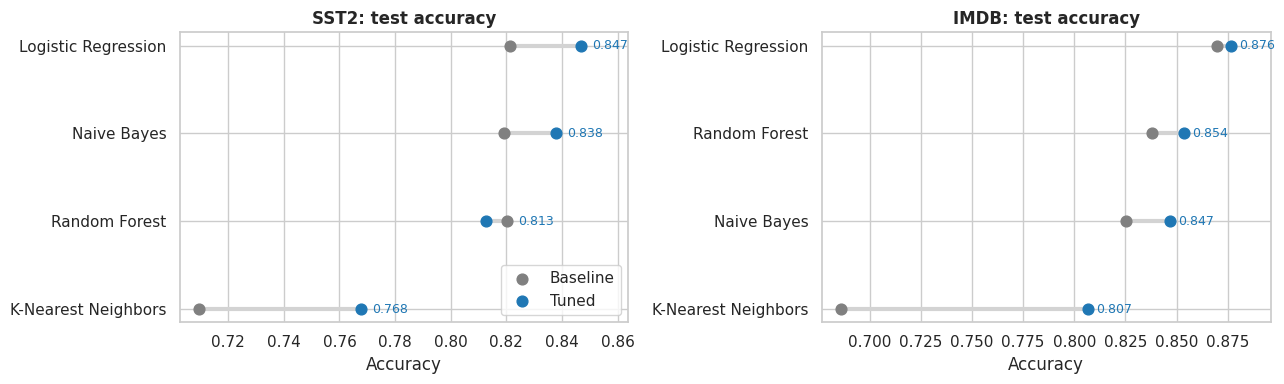

In [9]:
# Dot plot: baseline (grey) -> tuned (blue) test accuracy per model
sns.set_theme(style="whitegrid")
fig, axes = plt.subplots(1, 2, figsize=(13, 4))
for ax, ds in zip(axes, clean):
    sub = results[results.Dataset == ds].pivot(index="Model", columns="Setting", values="Accuracy")
    sub = sub.sort_values("Tuned")
    y = np.arange(len(sub))
    ax.hlines(y, sub["Baseline"], sub["Tuned"], color="lightgrey", lw=3)
    ax.scatter(sub["Baseline"], y, color="grey", s=60, label="Baseline", zorder=3)
    ax.scatter(sub["Tuned"], y, color="tab:blue", s=60, label="Tuned", zorder=3)
    for yi, (b, t) in enumerate(zip(sub["Baseline"], sub["Tuned"])):
        ax.text(max(b, t) + 0.004, yi, f"{t:.3f}", va="center", fontsize=9, color="tab:blue")
    ax.set_yticks(y, sub.index)
    ax.set_title(f"{ds}: test accuracy", fontweight="bold")
    ax.set_xlabel("Accuracy")
    ax.set_xlim(right=ax.get_xlim()[1] + 0.01)
axes[0].legend(loc="lower right")
plt.tight_layout(); plt.show()

## 7. How each hyperparameter affects the CV score
Each dot is one combination tried by the search. Because other parameters vary at the same time, read these as trends, not exact effects.

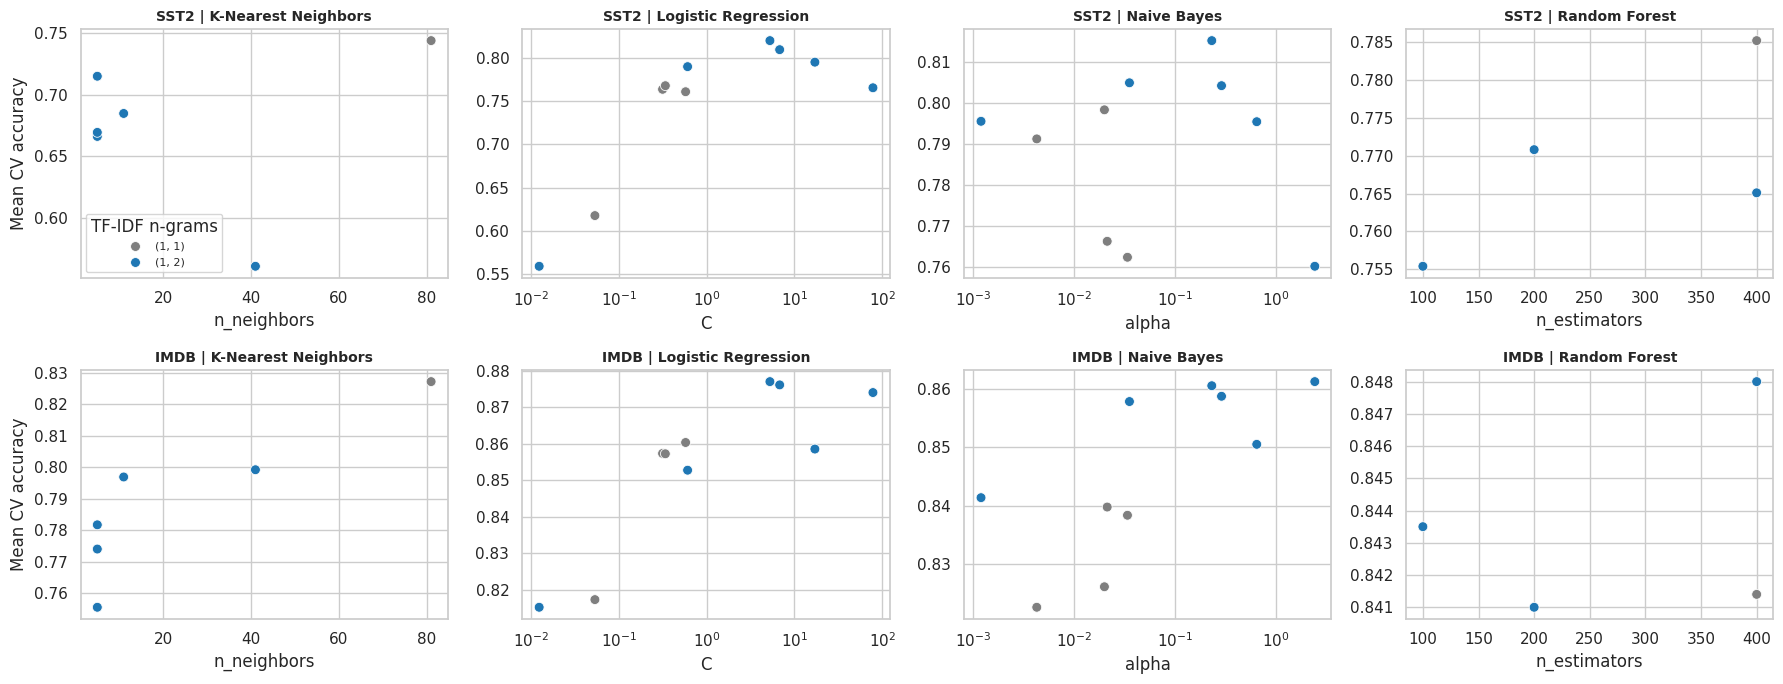

In [10]:
KEY_PARAMS = {
    "K-Nearest Neighbors": ("clf__n_neighbors", False),
    "Logistic Regression": ("clf__C", True),
    "Naive Bayes":         ("clf__alpha", True),
    "Random Forest":       ("clf__n_estimators", False),
}
fig, axes = plt.subplots(2, 4, figsize=(18, 7))
for col, (name, (param, logx)) in enumerate(KEY_PARAMS.items()):
    for row, ds in enumerate(clean):
        cvr = pd.DataFrame(searches[(ds, name)].cv_results_)
        ax = axes[row, col]
        hue = cvr["param_tfidf__ngram_range"].astype(str)
        sns.scatterplot(x=cvr[f"param_{param}"].astype(float), y=cvr["mean_test_accuracy"],
                        hue=hue, hue_order=["(1, 1)", "(1, 2)"],
                        palette={"(1, 1)": "tab:grey", "(1, 2)": "tab:blue"},
                        ax=ax, s=50, legend=(row == 0 and col == 0))
        if logx: ax.set_xscale("log")
        ax.set_title(f"{ds} | {name}", fontsize=10, fontweight="bold")
        ax.set_xlabel(param.split("__")[1]); ax.set_ylabel("Mean CV accuracy" if col == 0 else "")
axes[0, 0].legend(title="TF-IDF n-grams", fontsize=8)
plt.tight_layout(); plt.show()

In [11]:
# Top 5 configurations for any model, e.g. Logistic Regression on IMDB
def top_configs(ds, name, k=5):
    cvr = pd.DataFrame(searches[(ds, name)].cv_results_)
    cols = [c for c in cvr if c.startswith("param_")] + ["mean_test_accuracy", "std_test_accuracy", "mean_fit_time"]
    return cvr.sort_values("rank_test_accuracy")[cols].head(k).rename(columns=lambda c: c.replace("param_", "").replace("__", "."))

display(top_configs("IMDB", "Logistic Regression"))

,clf.C,clf.class_weight,tfidf.max_df,tfidf.max_features,tfidf.min_df,tfidf.ngram_range,tfidf.sublinear_tf,mean_test_accuracy,std_test_accuracy,mean_fit_time
7,5.262961,None,0.9,20000,1,"(1, 2)",False,0.8771,0.002115,6.071706
2,6.796578,balanced,0.9,20000,2,"(1, 2)",False,0.8762,0.002210,6.427686
5,78.527555,None,1.0,20000,5,"(1, 2)",True,0.8741,0.000910,5.987705
9,0.576249,None,1.0,5000,5,"(1, 1)",False,0.8604,0.000795,1.211439
8,17.123376,None,1.0,5000,2,"(1, 2)",False,0.8586,0.000862,5.844588


## 8. Cross-domain test (the paper's setup): train on SST-2, test on IMDB
The tuned SST-2 pipelines are applied to IMDB reviews they have never seen. This shows how well each model generalizes from short phrases to long reviews.

In [12]:
yte_imdb = data["IMDB"][1]["label"].values
rows = []
for name in MODELS:
    for setting, model in [("Baseline", baseline_fitted[("SST2", name)]),
                           ("Tuned", searches[("SST2", name)].best_estimator_)]:
        s = test_scores(model, clean["IMDB"][1], yte_imdb)
        rows.append({"Model": name, "Setting": setting, **s,
                     "Predicted positive": model.predict(clean["IMDB"][1]).mean()})
cross_df = pd.DataFrame(rows).round(4)
display(cross_df)

,Model,Setting,Accuracy,Precision,Recall,F1-Score,Predicted positive
0,K-Nearest Neighbors,Baseline,0.4690,0.4736,0.5560,0.5115,0.5870
1,K-Nearest Neighbors,Tuned,0.7290,0.7112,0.7712,0.7400,0.5422
2,Logistic Regression,Baseline,0.5226,0.5166,0.7044,0.5960,0.6818
3,Logistic Regression,Tuned,0.7964,0.8421,0.7296,0.7818,0.4332
4,Naive Bayes,Baseline,0.4926,0.4957,0.8528,0.6270,0.8602
5,Naive Bayes,Tuned,0.7954,0.8346,0.7368,0.7827,0.4414
6,Random Forest,Baseline,0.5480,0.5403,0.6440,0.5876,0.5960
7,Random Forest,Tuned,0.7124,0.7042,0.7324,0.7180,0.5200
